# v9 — Cabang bentuk gelombang EKG dengan AFDB + Chapman

**Pertanyaan.** v7–v8 membuktikan bahwa dari interval RR saja, ritme cepat yang teratur (sinus takikardia, AFL 2:1, SVT)
tidak bisa dipisahkan: model memilih antara alarm palsu pada sinus takikardia (paket v3.1) atau kehilangan AFL 2:1 dan SVT (8c).
Pembedanya ada di bentuk gelombang (gelombang P sinus vs gelombang flutter). v6 mencoba CNN EKG dengan 23 pasien dan overfit per
pasien. **Apakah arsitektur yang sama, dilatih dengan ±42 ribu pasien, bisa memisahkan ritme-ritme itu?**

**Data latih (semua varian sama).** AFDB fold latih + Chapman fold latih berlabel andal: Normal (SR/SB/ST/SA), AFIB, dan AFL
bagian Shaoxing (AFL Ningbo tidak andal, v8). Bentuk gelombang: lead II Chapman / kanal 0 AFDB, 50 Hz, bandpass 0,5–20 Hz,
500 sampel per window, dinormalisasi per window (praproses v6), sejajar dengan window interval RR (dibuktikan).

| Varian | Model | Hipotesis (ditetapkan sebelum melihat hasil) |
|---|---|---|
| `rr` kontrol | MicroTransformer interval RR (resep v5b) | Mirip 8c: alarm ST rendah, AFL 2:1 & SVT hilang |
| **`dual` 9a (utama)** | CNN EKG + RR (DualBranch v6) | Dibanding `rr`: recall AFL Shaoxing & alarm SVT naik (P ≥ 0,95), alarm ST tidak naik > 5 poin; di AFDB 08378 kembali ≥ 0,78 |
| `ekg` 9b | CNN EKG saja (ECGOnly v6) | Morfologi saja memisahkan ST dari AFL lebih baik daripada `rr` |
| `fusi` 9c | rata-rata probabilitas `rr` + `ekg` | Eksploratif (tanpa training) |

**Pembanding** dari cache v8 (lingkungan T4 yang sama, fold Chapman sama): v31 (resep v3.1), afdb (= v5b), 8c; paket v1/v2/v3.1.

**Kriteria kandidat produksi untuk 9a (ditetapkan sebelum hasil).** (1) AFDB: Macro-F1 vs v31 tidak lebih buruk (P > 0,05) dan
tidak ada pasien AFL yang turun ≥ 0,20; (2) Chapman: alarm sinus takikardia ≤ separuh paket v3.1, dan recall AFL (Shaoxing)
tidak lebih rendah dari paket v3.1; (3) alarm pada sinus takikardia asli ≥ 120 bpm ≤ 25% (paket v3.1: ±99%).

**Uji stres.** Ritme sintetis v3.2 hanya berisi interval RR, tanpa bentuk gelombang, jadi hanya dipakai untuk model `rr`. Untuk
model EKG, uji stresnya adalah 6.937 sinus takikardia **asli** Chapman per pita detak (lebih kuat dari data sintetis).

**Prasyarat.** Hasil v8 (`../cache/v8/`: window Chapman, OOF v31/afdb/8c) dan fold resmi. Data mentah AFDB & Chapman diunduh
ulang bila belum ada (mirror S3 resmi). Di Colab: jalankan dengan cache v8 di Google Drive (lihat README).

In [1]:
import os, sys, subprocess, shutil, time
from pathlib import Path
sys.path.insert(0, os.getcwd())
try:
    import wfdb  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--progress-bar", "off", "wfdb"], check=True)
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import gelombang as G
C8, E6, cv, T = G.C8, G.E6, G.cv, G.T
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)
print("commit repo:", subprocess.run(["git", "log", "-1", "--format=%h %s"], capture_output=True, text=True).stdout.strip())
print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | CPU {os.cpu_count()} | GPU",
      ", ".join(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())) or "TIDAK ADA",
      "| QUICK" if G.QUICK else "")
assert (G.V8_OOF / "afdb_chapman_bersih_r0.npz").exists() and C8.CH_WIN.exists(), "hasil v8 tidak ditemukan di ../cache/v8"


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

commit repo: 6cb0351 feat(v8): hasil data eksternal Chapman-Shaoxing (tidak dikemas)


Python 3.13.15 | torch 2.11.0+cu128 | CPU 4 | GPU Tesla T4, Tesla T4 


## 1. Data

AFDB & fold (dibuktikan sama dengan tim), window RR Chapman dari v8, lalu potongan EKG yang sejajar: AFDB (v6, selisih jumlah
R-peak harus 0) dan Chapman (IBI dari sinyal yang sama harus identik dengan window RR v8).

In [2]:
t0 = time.perf_counter()
print("AFDB:", C8.ensure_afdb()["identik_bit_demi_bit"], "| fold:", C8.ensure_folds().shape)
print("EKG AFDB:", G.ensure_afdb_ecg())
C8.download_chapman()
print("EKG Chapman:", G.build_chapman_ecg())
ch = C8.load_chapman()
use = G.train_mask(ch)
y_afdb = np.load(C8.DATA_STD)["y"]
print(f"selesai {time.perf_counter() - t0:.0f}s")
display(pd.DataFrame({"AFDB (window)": np.bincount(y_afdb, minlength=3), "Chapman andal (pasien)": np.bincount(ch["cls"][use], minlength=3)},
                     index=["Normal", "AFIB", "AFL"]))

AFDB: True | fold: (5, 165978)


EKG AFDB: {'n': 165978, 'mismatch': 'cache'}


EKG Chapman: {'n': 42040, 'tidak_sejajar': 0}
selesai 2s


,AFDB (window),Chapman andal (pasien)
Normal,99000,32025
AFIB,65826,1696
AFL,1152,416


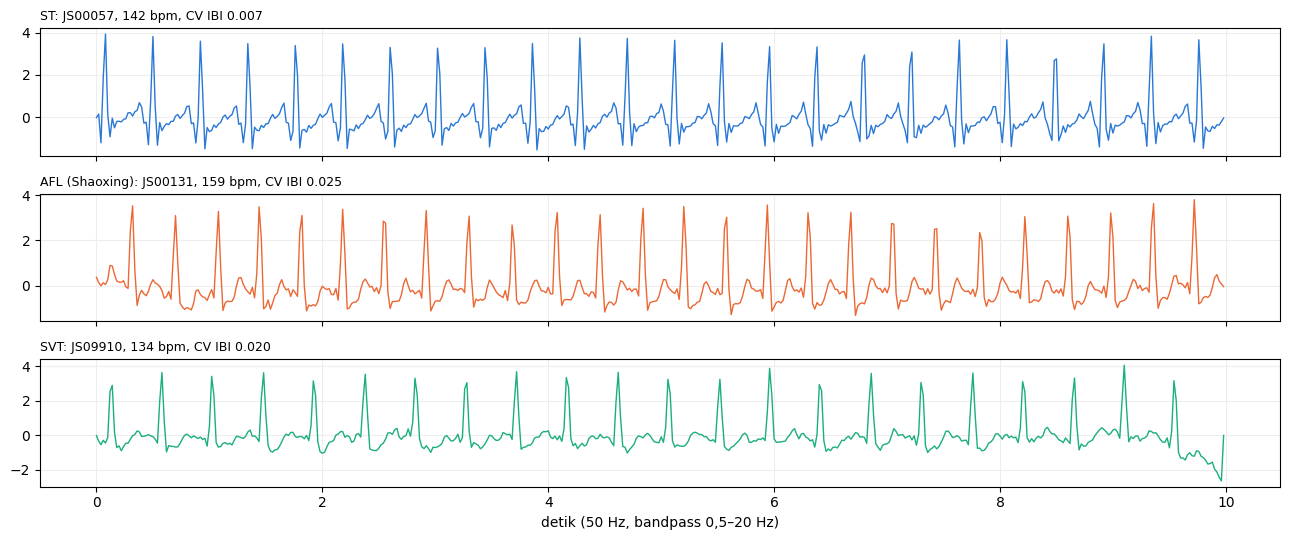

In [3]:
Ec = np.load(G.CH_ECG)["ecg"]
fig, axes = plt.subplots(3, 1, figsize=(13, 5.5), sharex=True)
tt = np.arange(E6.N_SAMP) / E6.FS
for ax, (g, col) in zip(axes, (("ST", "#2a78d6"), ("AFL", "#eb6834"), ("SVT", "#1baf7a"))):
    m = (ch["rhythm"] == g) & ~((g == "AFL") & C8.is_ningbo(ch["record"])) & (ch["hr"] >= 130) & (ch["hr"] < 160)
    i = (np.flatnonzero(m) if m.any() else np.flatnonzero(ch["rhythm"] == g))[0]
    ax.plot(tt, Ec[i].astype(float), color=col, lw=1)
    ax.set_title(f"{g}{' (Shaoxing)' if g == 'AFL' else ''}: {ch['record'][i]}, {ch['hr'][i]:.0f} bpm, CV IBI {ch['cv'][i]:.3f}", loc="left", fontsize=9)
    ax.grid(color="0.93")
axes[-1].set_xlabel("detik (50 Hz, bandpass 0,5–20 Hz)")
plt.tight_layout(); plt.show()

Contoh di atas: tiga ritme cepat (130–160 bpm) yang tampak serupa dari interval RR. Pada sinus takikardia ada gelombang P sebelum
tiap QRS; pada AFL ada gelombang flutter "gigi gergaji" di antara QRS. Apakah CNN bisa memanfaatkannya?

## 2. Training (3 varian × 5 ulangan × 5 fold)

Fungsi training diimpor tanpa diubah: `ekg.train` (v6; bobot lunak, augmentasi polaritas) untuk `dual`/`ekg`, dan
`latih.train_dl_weighted` (v5) untuk `rr`. Satu proses per GPU; job yang sudah ada dilewati.

In [4]:
G.run_all_jobs()

15 job tersisa dari 15, 2 proses (satu per GPU)


  [ 45.8 mnt] dual  ulangan 0: 546 s/fold


  [ 50.4 mnt] ekg   ulangan 0: 601 s/fold


  [ 53.5 mnt] rr    ulangan 0: 92 s/fold


  [103.4 mnt] dual  ulangan 1: 633 s/fold
  [103.4 mnt] ekg   ulangan 1: 508 s/fold
  [103.4 mnt] rr    ulangan 1: 84 s/fold


...

  [156.3 mnt] rr    ulangan 2: 89 s/fold


  [206.7 mnt] dual  ulangan 3: 633 s/fold
  [206.7 mnt] ekg   ulangan 3: 508 s/fold
  [206.7 mnt] rr    ulangan 3: 88 s/fold


  [251.9 mnt] dual  ulangan 4: 547 s/fold


  [256.9 mnt] ekg   ulangan 4: 600 s/fold


  [259.1 mnt] rr    ulangan 4: 86 s/fold


## 3. Hasil di AFDB (protokol v3)

Δ berpasangan terhadap v31 (referensi), terhadap `rr` (kontrol: data sama, tanpa bentuk gelombang), dan terhadap 8c (v8).
Perhatikan juga rentang bias cross-fit: bias yang melompat antar fold adalah tanda overfit per pasien (pelajaran v6).

In [5]:
t0 = time.perf_counter()
res = G.evaluate()
print(f"evaluasi {time.perf_counter() - t0:.0f}s")
lab = res["labels"]
A = res["afdb"]
order = [k for k in ("v1", "v31", "afdb", "afdb_chapman_bersih", "rr", "dual", "ekg", "fusi") if k in A["rows"]]
display(pd.DataFrame([{"model": lab[k], **{m: fmt(A["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "Normal R")},
                       "alarm AFL palsu/jam": fmt(A["episodes"][k]["alarm/jam"]),
                       "deteksi episode AFL": fmt(A["episodes"][k]["deteksi episode"], 2)} for k in order]).set_index("model"))
pr = []
for k in ("rr", "dual", "ekg", "fusi"):
    for ref, P in (("v31", A["pairs"].get(k)), ("rr", A["pairs_rr"].get(k)), ("8c", A["pairs_8c"].get(k))):
        if P is None:
            continue
        for m in ("Macro-F1", "AFL R", "Normal R"):
            pr.append({"model": lab[k], "vs": ref, "metrik": m, "Δ": round(P[m][0], 3), "CI 95%": f"{P[m][1]:+.3f} … {P[m][2]:+.3f}",
                       "P(Δ>0)": round(P[m][3], 3), "vonis": verdict(P[m][3])})
display(pd.DataFrame(pr).set_index(["model", "vs", "metrik"]))
display(pd.DataFrame({lab[k]: np.round(A["afl_recall"][k], 2) for k in order}, index=A["afl_patients"]).rename_axis("recall AFL"))
display(pd.DataFrame({lab[k]: {"AFL palsu/ulangan": round(A["fp"][k]["total"]), "dari pasien tanpa AFL": round(A["fp"][k]["pasien_lain"]),
                               "bias median": np.round(A["bias"][k]["median"], 2).tolist() if k in A["bias"] else "—",
                               "bias min…max (AFL)": (f"{A['bias'][k]['min'][2]:.2f} … {A['bias'][k]['max'][2]:.2f}" if k in A["bias"] else "—")}
                      for k in order}))

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


evaluasi 3926s


,Macro-F1,AFL F1,AFL R,Normal R,alarm AFL palsu/jam,deteksi episode AFL
model,,,,,,
"v31 (resep v3.1, AFDB saja; v8)",0.830 [0.67–0.92],0.647 [0.17–0.89],0.600 [0.14–0.93],0.920 [0.84–0.96],0.560 [0.16–1.08],0.77 [0.49–0.94]
afdb (= v5b; v8),0.835 [0.67–0.90],0.655 [0.17–0.85],0.607 [0.15–0.85],0.928 [0.85–0.97],0.476 [0.07–1.01],0.74 [0.44–0.92]
"8c: RR, tanpa AFL Chapman (v8)",0.799 [0.66–0.83],0.537 [0.15–0.60],0.479 [0.14–0.57],0.924 [0.85–0.97],0.833 [0.34–1.42],0.77 [0.55–0.93]
"kontrol: RR saja, AFDB + Chapman andal",0.783 [0.67–0.81],0.493 [0.15–0.57],0.436 [0.13–0.55],0.917 [0.84–0.96],0.640 [0.22–1.16],0.75 [0.49–0.91]
"9a: CNN EKG + RR, AFDB + Chapman andal",0.687 [0.64–0.77],0.209 [0.02–0.45],0.404 [0.02–0.63],0.928 [0.88–0.97],2.655 [0.16–7.40],0.60 [0.24–0.84]
"9b: CNN EKG saja, AFDB + Chapman andal",0.651 [0.60–0.68],0.191 [0.06–0.22],0.452 [0.05–0.68],0.889 [0.78–0.97],2.580 [0.36–5.79],0.63 [0.27–0.85]
9c: fusi rr + ekg,0.716 [0.65–0.79],0.273 [0.04–0.50],0.465 [0.03–0.72],0.955 [0.93–0.98],1.685 [0.08–4.73],0.74 [0.38–0.94]


Δ           CI 95%  P(Δ>0)             vonis
model                                  vs  metrik                                                    
kontrol: RR saja, AFDB + Chapman andal v31 Macro-F1 -0.048  -0.150 … +0.011   0.162  tidak terbedakan
                                           AFL R    -0.164  -0.562 … +0.008   0.261  tidak terbedakan
                                           Normal R -0.003  -0.008 … +0.000   0.037       lebih buruk
                                       8c  Macro-F1 -0.016  -0.042 … +0.013   0.111  tidak terbedakan
                                           AFL R    -0.043  -0.147 … +0.007   0.261  tidak terbedakan
                                           Normal R -0.007  -0.014 … -0.003   0.000       lebih buruk
9a: CNN EKG + RR, AFDB + Chapman andal v31 Macro-F1 -0.143  -0.263 … +0.033   0.073  tidak terbedakan
                                           AFL R    -0.195  -0.866 … +0.101   0.300  tidak terbedakan
                                           Normal R  0.008  -0.066 … +0.100   0.561  tidak terbedakan
                                       rr  Macro-F1 -0.096  -0.138 … +0.029   0.079  tidak terbedakan
                                           AFL R    -0.032  -0.307 … +0.093   0.408  tidak terbedakan
                                           Normal R  0.011  -0.062 … +0.106   0.598  tidak terbedakan
                                       8c  Macro-F1 -0.112  -0.161 … +0.035   0.083  tidak terbedakan
                                           AFL R    -0.075  -0.456 … +0.094   0.340  tidak terbedakan
                                           Normal R  0.004  -0.068 … +0.092   0.529  tidak terbedakan
9b: CNN EKG saja, AFDB + Chapman andal v31 Macro-F1 -0.179  -0.291 … -0.018   0.019       lebih buruk
                                           AFL R    -0.147  -0.839 … +0.154   0.359  tidak terbedakan
                                           Normal R -0.032  -0.156 … +0.095   0.332  tidak terbedakan
                                       rr  Macro-F1 -0.132  -0.200 … -0.016   0.018       lebih buruk
                                           AFL R     0.016  -0.277 … +0.147   0.649  tidak terbedakan
                                           Normal R -0.028  -0.153 … +0.102   0.357  tidak terbedakan
                                       8c  Macro-F1 -0.148  -0.210 … -0.015   0.018       lebih buruk
                                           AFL R    -0.027  -0.424 … +0.148   0.444  tidak terbedakan
                                           Normal R -0.036  -0.158 … +0.090   0.308  tidak terbedakan
9c: fusi rr + ekg                      v31 Macro-F1 -0.114  -0.240 … +0.048   0.096  tidak terbedakan
                                           AFL R    -0.135  -0.841 … +0.189   0.364  tidak terbedakan
                                           Normal R  0.034  -0.013 … +0.101   0.898  tidak terbedakan
                                       rr  Macro-F1 -0.067  -0.100 … +0.047   0.097  tidak terbedakan
                                           AFL R     0.029  -0.279 … +0.181   0.647  tidak terbedakan
                                           Normal R  0.038  -0.010 … +0.105   0.915  tidak terbedakan
                                       8c  Macro-F1 -0.083  -0.135 … +0.060   0.097  tidak terbedakan
                                           AFL R    -0.014  -0.426 … +0.183   0.434  tidak terbedakan
                                           Normal R  0.030  -0.015 … +0.093   0.879  tidak terbedakan

,"v31 (resep v3.1, AFDB saja; v8)",afdb (= v5b; v8),"8c: RR, tanpa AFL Chapman (v8)","kontrol: RR saja, AFDB + Chapman andal","9a: CNN EKG + RR, AFDB + Chapman andal","9b: CNN EKG saja, AFDB + Chapman andal",9c: fusi rr + ekg
recall AFL,,,,,,,
04043,0.60,0.80,0.80,0.80,0.00,0.00,0.40
04908,0.93,0.91,0.89,0.91,0.87,0.97,0.97
04936,0.51,0.57,0.52,0.52,0.62,0.67,0.71
06426,0.18,0.25,0.18,0.16,0.12,0.17,0.25
07910,0.00,0.00,0.01,0.00,0.07,0.12,0.00
08215,0.00,0.00,0.00,0.00,0.00,0.00,0.00
08378,0.98,0.88,0.51,0.35,0.00,0.03,0.03


,"v31 (resep v3.1, AFDB saja; v8)",afdb (= v5b; v8),"8c: RR, tanpa AFL Chapman (v8)","kontrol: RR saja, AFDB + Chapman andal","9a: CNN EKG + RR, AFDB + Chapman andal","9b: CNN EKG saja, AFDB + Chapman andal",9c: fusi rr + ekg
AFL palsu/ulangan,293,279,345,313,2878,3809,2771
dari pasien tanpa AFL,33,18,94,66,49,85,19
bias median,"[0.0, -0.5, -4.5]","[0.0, -0.5, -2.5]","[0.0, 0.0, -1.5]","[0.0, 0.25, -1.5]","[0.0, 3.0, -7.0]","[0.0, 2.0, 1.75]","[0.0, 0.0, -1.0]"
bias min…max (AFL),-5.25 … -3.75,-3.50 … -1.25,-2.50 … -0.75,-2.50 … -0.25,-7.00 … 3.00,-7.00 … 3.00,-2.25 … 0.50


## 4. Hasil di Chapman (label andal)

Pasien Chapman uji tidak pernah ikut dilatih (fold v8). Bias kelas dari AFDB, seperti di produksi.

In [6]:
Cc = res["chapman"]
if Cc["paket_catatan"]:
    print("⚠", Cc["paket_catatan"])
print("pasien untuk metrik 3 kelas:", Cc["n_metrik"])
keys = [k for k in ("v1_paket", "v31_paket", "v31", "afdb_chapman_bersih", "rr", "dual", "ekg", "fusi") if k in Cc["metrics"]]
display(pd.DataFrame([{"model": lab[k], **{m: fmt(Cc["metrics"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL R", "AFIB R", "Normal R")}}
                      for k in keys]).set_index("model"))
pr = []
for ref in ("rr", "v31_paket"):
    for k in ("dual", "ekg", "fusi"):
        for m in ("Macro-F1", "AFL R", "Normal R"):
            p = Cc["pairs"][ref][k][m]
            pr.append({"model": lab[k], "vs": lab[ref], "metrik": m, "Δ": round(p[0], 3), "CI 95%": f"{p[1]:+.3f} … {p[2]:+.3f}",
                       "P(Δ>0)": round(p[3], 3), "vonis": verdict(p[3])})
display(pd.DataFrame(pr).set_index(["model", "vs", "metrik"]))

pasien untuk metrik 3 kelas: {'Normal': 32025, 'AFIB': 1696, 'AFL': 416}


,Macro-F1,AFL F1,AFL R,AFIB R,Normal R
model,,,,,
paket v1,0.517 [0.51–0.52],0.083 [0.07–0.09],0.370 [0.32–0.42],0.913 [0.90–0.93],0.839 [0.83–0.84]
paket produksi v3.1,0.520 [0.51–0.53],0.078 [0.06–0.09],0.243 [0.20–0.28],0.953 [0.94–0.96],0.865 [0.86–0.87]
"v31 (resep v3.1, AFDB saja; v8)",0.531 [0.53–0.54],0.084 [0.07–0.10],0.232 [0.19–0.27],0.942 [0.93–0.95],0.882 [0.88–0.88]
"8c: RR, tanpa AFL Chapman (v8)",0.583 [0.57–0.59],0.094 [0.07–0.12],0.078 [0.06–0.10],0.942 [0.93–0.95],0.956 [0.95–0.96]
"kontrol: RR saja, AFDB + Chapman andal",0.594 [0.58–0.60],0.131 [0.10–0.16],0.136 [0.11–0.17],0.945 [0.94–0.95],0.951 [0.95–0.95]
"9a: CNN EKG + RR, AFDB + Chapman andal",0.739 [0.73–0.75],0.348 [0.31–0.39],0.225 [0.19–0.26],0.968 [0.96–0.97],0.993 [0.99–0.99]
"9b: CNN EKG saja, AFDB + Chapman andal",0.762 [0.75–0.77],0.425 [0.39–0.46],0.309 [0.28–0.34],0.948 [0.94–0.95],0.992 [0.99–0.99]
9c: fusi rr + ekg,0.707 [0.69–0.72],0.276 [0.24–0.31],0.206 [0.17–0.24],0.955 [0.95–0.96],0.988 [0.99–0.99]


Δ           CI 95%  P(Δ>0)             vonis
model                                  vs                                     metrik                                                    
9a: CNN EKG + RR, AFDB + Chapman andal kontrol: RR saja, AFDB + Chapman andal Macro-F1  0.145  +0.132 … +0.159   1.000        lebih baik
                                                                              AFL R     0.090  +0.060 … +0.120   1.000        lebih baik
                                                                              Normal R  0.043  +0.041 … +0.045   1.000        lebih baik
9b: CNN EKG saja, AFDB + Chapman andal kontrol: RR saja, AFDB + Chapman andal Macro-F1  0.168  +0.155 … +0.181   1.000        lebih baik
                                                                              AFL R     0.173  +0.138 … +0.206   1.000        lebih baik
                                                                              Normal R  0.042  +0.040 … +0.044   1.000        lebih baik
9c: fusi rr + ekg                      kontrol: RR saja, AFDB + Chapman andal Macro-F1  0.114  +0.104 … +0.122   1.000        lebih baik
                                                                              AFL R     0.070  +0.049 … +0.090   1.000        lebih baik
                                                                              Normal R  0.038  +0.036 … +0.040   1.000        lebih baik
9a: CNN EKG + RR, AFDB + Chapman andal paket produksi v3.1                    Macro-F1  0.219  +0.206 … +0.232   1.000        lebih baik
                                                                              AFL R    -0.017  -0.058 … +0.022   0.192  tidak terbedakan
                                                                              Normal R  0.128  +0.125 … +0.132   1.000        lebih baik
9b: CNN EKG saja, AFDB + Chapman andal paket produksi v3.1                    Macro-F1  0.242  +0.230 … +0.254   1.000        lebih baik
                                                                              AFL R     0.066  +0.024 … +0.104   1.000        lebih baik
                                                                              Normal R  0.127  +0.124 … +0.131   1.000        lebih baik
9c: fusi rr + ekg                      paket produksi v3.1                    Macro-F1  0.188  +0.176 … +0.199   1.000        lebih baik
                                                                              AFL R    -0.037  -0.072 … -0.005   0.012       lebih buruk
                                                                              Normal R  0.123  +0.120 … +0.127   1.000        lebih baik

### Sinus takikardia asli, SVT, dan AFL cepat (uji stres untuk model EKG)

In [7]:
rows = [{"kelompok": f"ST {b} bpm", "pasien": v["n"], **{lab[k]: fmt(v[k], 2) for k in keys}} for b, v in Cc["st_bands"].items()]
rows += [{"kelompok": "ST semua", "pasien": Cc["st_all"]["n"], **{lab[k]: fmt(Cc["st_all"][k], 2) for k in keys}},
         {"kelompok": "SR/SB/SA", "pasien": Cc["sinus_alarm"]["n"], **{lab[k]: fmt(Cc["sinus_alarm"][k], 2) for k in keys}},
         {"kelompok": "SVT (alarm = bagus)", "pasien": Cc["svt_alarm"]["n"], **{lab[k]: fmt(Cc["svt_alarm"][k], 2) for k in keys}}]
display(pd.DataFrame(rows).set_index("kelompok").rename_axis("ditebak AFIB/AFL"))
display(pd.DataFrame([{"AFL Shaoxing": b, "pasien": v["n"], **{lab[k]: (f"{v[k]:.0%}" if v[k] is not None else "—") for k in keys}}
                      for b, v in Cc["afl_bands"].items()]).set_index("AFL Shaoxing").rename_axis("AFL terdeteksi"))
display(pd.DataFrame([{"ritme": g, "pasien": v["n"], **{lab[k]: f"{v[k][0]:.0%} / {v[k][1]:.0%} / {v[k][2]:.0%}" for k in keys}}
                      for g, v in Cc["rhythm"].items()]).set_index("ritme"))

,pasien,paket v1,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)","8c: RR, tanpa AFL Chapman (v8)","kontrol: RR saja, AFDB + Chapman andal","9a: CNN EKG + RR, AFDB + Chapman andal","9b: CNN EKG saja, AFDB + Chapman andal",9c: fusi rr + ekg
ditebak AFIB/AFL,,,,,,,,,
ST 100–110 bpm,3415,0.08 [0.07–0.09],0.06 [0.06–0.07],0.06 [0.05–0.07],0.04 [0.03–0.04],0.04 [0.03–0.04],0.01 [0.01–0.01],0.01 [0.01–0.01],0.01 [0.01–0.01]
ST 110–120 bpm,1639,0.82 [0.80–0.84],0.55 [0.52–0.57],0.41 [0.39–0.43],0.06 [0.05–0.07],0.06 [0.05–0.07],0.01 [0.01–0.01],0.01 [0.01–0.02],0.01 [0.01–0.02]
ST 120–130 bpm,783,0.98 [0.97–0.99],0.98 [0.97–0.99],0.92 [0.91–0.93],0.09 [0.07–0.10],0.11 [0.09–0.12],0.02 [0.01–0.03],0.03 [0.02–0.04],0.03 [0.02–0.04]
ST 130–140 bpm,484,1.00 [0.99–1.00],1.00 [1.00–1.00],0.99 [0.98–0.99],0.20 [0.17–0.23],0.27 [0.25–0.31],0.03 [0.01–0.04],0.03 [0.02–0.04],0.08 [0.07–0.10]
ST 140–150 bpm,199,1.00 [1.00–1.00],1.00 [1.00–1.00],1.00 [0.99–1.00],0.59 [0.53–0.65],0.70 [0.66–0.75],0.03 [0.01–0.05],0.03 [0.01–0.05],0.19 [0.16–0.22]
ST 150–∞ bpm,277,1.00 [1.00–1.00],1.00 [1.00–1.00],1.00 [1.00–1.00],0.27 [0.22–0.31],0.43 [0.38–0.48],0.03 [0.01–0.04],0.04 [0.02–0.06],0.11 [0.09–0.13]
ST semua,6937,0.49 [0.48–0.50],0.42 [0.40–0.43],0.38 [0.37–0.39],0.09 [0.08–0.10],0.11 [0.10–0.12],0.02 [0.01–0.02],0.02 [0.02–0.02],0.03 [0.03–0.03]
SR/SB/SA,25088,0.07 [0.07–0.07],0.06 [0.05–0.06],0.05 [0.05–0.05],0.03 [0.03–0.03],0.03 [0.03–0.03],0.00 [0.00–0.00],0.00 [0.00–0.01],0.01 [0.01–0.01]
SVT (alarm = bagus),556,0.99 [0.99–1.00],0.99 [0.98–1.00],0.99 [0.98–0.99],0.26 [0.23–0.29],0.39 [0.36–0.43],0.56 [0.53–0.59],0.73 [0.70–0.76],0.53 [0.50–0.56]


,pasien,paket v1,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)","8c: RR, tanpa AFL Chapman (v8)","kontrol: RR saja, AFDB + Chapman andal","9a: CNN EKG + RR, AFDB + Chapman andal","9b: CNN EKG saja, AFDB + Chapman andal",9c: fusi rr + ekg
AFL terdeteksi,,,,,,,,,
0–100,158,1%,0%,0%,0%,0%,17%,23%,5%
100–130,125,30%,14%,13%,1%,1%,14%,23%,8%
130–160,109,83%,57%,55%,27%,42%,37%,47%,49%
160–∞,24,100%,88%,87%,10%,40%,42%,51%,57%


,pasien,paket v1,paket produksi v3.1,"v31 (resep v3.1, AFDB saja; v8)","8c: RR, tanpa AFL Chapman (v8)","kontrol: RR saja, AFDB + Chapman andal","9a: CNN EKG + RR, AFDB + Chapman andal","9b: CNN EKG saja, AFDB + Chapman andal",9c: fusi rr + ekg
ritme,,,,,,,,,
AFIB,1696,4% / 91% / 5%,4% / 95% / 0%,6% / 94% / 0%,6% / 94% / 0%,5% / 94% / 0%,3% / 97% / 0%,5% / 95% / 1%,4% / 96% / 0%
AFL (Shaoxing),416,13% / 50% / 37%,14% / 61% / 24%,17% / 60% / 23%,37% / 55% / 8%,32% / 54% / 14%,22% / 55% / 23%,20% / 49% / 31%,27% / 53% / 21%
"AFL (Ningbo, label tidak andal)",7192,10% / 80% / 10%,12% / 84% / 4%,13% / 83% / 4%,17% / 82% / 1%,15% / 82% / 2%,12% / 85% / 4%,12% / 82% / 6%,14% / 83% / 4%
SA,1612,32% / 67% / 2%,42% / 58% / 0%,55% / 45% / 0%,68% / 32% / 0%,67% / 33% / 0%,98% / 2% / 0%,98% / 2% / 0%,94% / 6% / 0%
SB,15654,98% / 2% / 0%,98% / 2% / 0%,98% / 2% / 0%,99% / 1% / 0%,99% / 1% / 0%,100% / 0% / 0%,100% / 0% / 0%,100% / 0% / 0%
SR,7822,95% / 3% / 2%,97% / 2% / 1%,97% / 2% / 1%,99% / 1% / 0%,99% / 1% / 0%,100% / 0% / 0%,99% / 1% / 0%,100% / 0% / 0%
ST,6937,51% / 8% / 41%,58% / 13% / 29%,62% / 13% / 25%,91% / 6% / 3%,89% / 6% / 5%,98% / 1% / 0%,98% / 1% / 1%,97% / 1% / 1%
AT,134,28% / 40% / 32%,31% / 52% / 16%,31% / 54% / 15%,49% / 48% / 3%,45% / 49% / 7%,61% / 33% / 6%,59% / 30% / 11%,58% / 32% / 10%
AVRT,21,67% / 0% / 33%,67% / 5% / 29%,70% / 7% / 24%,82% / 4% / 14%,82% / 5% / 13%,77% / 12% / 10%,64% / 19% / 17%,75% / 8% / 17%


## 5. Uji stres sintetis (model interval RR saja) dan sensitivitas tanpa 04936

In [8]:
display(pd.DataFrame({lab[k]: res["threshold"][k] for k in res["threshold"]}).T.rename_axis("ambang (bpm) < 50% Normal"))
sens = []
for lab_s, s in A["sens"].items():
    for k, r in s["rows"].items():
        sens.append({"data": lab_s, "model": lab[k], **{m: fmt(r[m]) for m in ("Macro-F1", "AFL F1", "AFL R")},
                     "P(v31 > model)": round(s["pairs_v31_minus"][k][3], 2) if k in s["pairs_v31_minus"] else "—"})
display(pd.DataFrame(sens).set_index(["data", "model"]))

,tanpa variasi,seragam ±10 ms,Gauss sd 10 ms,Gauss sd 20 ms
ambang (bpm) < 50% Normal,,,,
"kontrol: RR saja, AFDB + Chapman andal",135,135,135,120
"v31 (resep v3.1, AFDB saja; v8)",115,115,115,115
"8c: RR, tanpa AFL Chapman (v8)",135,135,135,120


Macro-F1             AFL F1              AFL R P(v31 > model)
data         model                                                                                                         
semua pasien v31 (resep v3.1, AFDB saja; v8)         0.830 [0.67–0.92]  0.647 [0.17–0.89]  0.600 [0.14–0.93]              —
             afdb (= v5b; v8)                        0.835 [0.67–0.90]  0.655 [0.17–0.85]  0.607 [0.15–0.85]           0.32
             8c: RR, tanpa AFL Chapman (v8)          0.799 [0.66–0.83]  0.537 [0.15–0.60]  0.479 [0.14–0.57]           0.77
             kontrol: RR saja, AFDB + Chapman andal  0.783 [0.67–0.81]  0.493 [0.15–0.57]  0.436 [0.13–0.55]           0.84
             9a: CNN EKG + RR, AFDB + Chapman andal  0.687 [0.64–0.77]  0.209 [0.02–0.45]  0.404 [0.02–0.63]           0.93
             9b: CNN EKG saja, AFDB + Chapman andal  0.651 [0.60–0.68]  0.191 [0.06–0.22]  0.452 [0.05–0.68]           0.98
             9c: fusi rr + ekg                       0.716 [0.65–0.79]  0.273 [0.04–0.50]  0.465 [0.03–0.72]            0.9
tanpa 04936  v31 (resep v3.1, AFDB saja; v8)         0.859 [0.62–0.93]  0.734 [0.02–0.92]  0.689 [0.02–0.93]              —
             afdb (= v5b; v8)                        0.837 [0.63–0.89]  0.656 [0.03–0.81]  0.601 [0.03–0.79]           0.66
             8c: RR, tanpa AFL Chapman (v8)          0.727 [0.63–0.80]  0.319 [0.03–0.52]  0.257 [0.03–0.70]           0.69
             kontrol: RR saja, AFDB + Chapman andal  0.693 [0.62–0.80]  0.223 [0.02–0.54]  0.159 [0.02–0.68]           0.71
             9a: CNN EKG + RR, AFDB + Chapman andal  0.668 [0.63–0.70]  0.134 [0.02–0.23]  0.153 [0.01–0.76]           0.86
             9b: CNN EKG saja, AFDB + Chapman andal  0.658 [0.62–0.70]  0.175 [0.06–0.27]  0.189 [0.05–0.74]           0.88
             9c: fusi rr + ekg                       0.698 [0.67–0.74]  0.237 [0.13–0.42]  0.195 [0.09–0.76]           0.77

In [9]:
G.CACHE_OUT.mkdir(parents=True, exist_ok=True)
(G.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
dest = Path("/kaggle/working/v9_hasil.zip") if Path("/kaggle/working").exists() else G.CACHE_OUT / "v9_hasil.zip"
path, mb = G.pack_results(dest)
print(f"Ringkasan → cache/v9/ringkasan.json | hasil → {path} ({mb:.0f} MB)")

Ringkasan → cache/v9/ringkasan.json | hasil → /kaggle/working/v9_hasil.zip (109 MB)


## 6. Kesimpulan

**Bentuk gelombang EKG memuat informasi yang hilang dari interval RR. Pada pasien Chapman yang tidak ikut dilatih, alarm palsu
sinus takikardia hampir hilang. Tetapi model belum menyeberang ke AFDB (Holter): alarm AFL palsu melonjak dan 08378 hilang.
Paket produksi tetap v3.1; v9 tidak dikemas.**

- **Data.** EKG AFDB dan Chapman dibuktikan sejajar dengan window interval RR (0 selisih di 165.978 dan 42.040 window).
- **Chapman (34 ribu pasien uji eksternal, label andal):**
  - alarm pada sinus takikardia asli: paket v3.1 42%, kontrol rr 11%, **9a 2%**, 9b 2%; di 140–150 bpm rr 70% → 9a 3%;
  - Macro-F1: paket 0,520, rr 0,594, **9a 0,739**, 9b 0,762; recall Normal 9a 0,993;
  - SVT dibunyikan alarm: rr 39%, 9a 56%, 9b 73% (paket 99%);
  - recall AFL Shaoxing: paket 0,243, rr 0,136, 9a 0,225 (tidak terbedakan dari paket, P = 0,19), 9b 0,309 (lebih baik, P = 1,00);
  - semua Δ 9a/9b/9c terhadap kontrol rr: lebih baik (P = 1,00).
- **AFDB (protokol v3):**
  - Macro-F1 9a 0,687 vs v31 0,830 (Δ −0,143, P = 0,07); 9b 0,651 (lebih buruk, P = 0,02); fusi 0,716 (P = 0,10);
  - AFL palsu 293 → 2.878 per ulangan (9a), hampir semua dari window non-AFL milik pasien AFL; alarm AFL palsu 0,56 → 2,7/jam;
  - recall AFL 08378 0,98 → 0,00 dan 04043 0,60 → 0,00;
  - bias AFL cross-fit melompat −7 … +3 (kedua batas grid), tanda bahaya yang sama dengan v6.
- **Hipotesis.** H1 (9a vs rr di Chapman: AFL & SVT naik, ST tidak naik) terbukti. H2 (08378 kembali ≥ 0,78) ditolak.
- **Kriteria kandidat 9a:** alarm ST lolos (2% vs 42%; ≥ 120 bpm maks 3%), AFL Chapman tidak terbedakan dari paket; tetapi per pasien
  AFDB **tidak lolos** (08378, 04043), dan Macro-F1 AFDB hanya lolos tipis (P = 0,07).

**Untuk proyek.** Batasnya bergeser. Setelah v3–v8, yang membatasi adalah informasi (interval RR) dan jumlah pasien. Sekarang yang
membatasi adalah **pergeseran domain** antara EKG klinis istirahat (Chapman) dan Holter rawat jalan (AFDB). Perangkat SIHEDAF
mungkin mirip salah satunya, atau tidak mirip keduanya.

**Langkah berikutnya (v10).**
1. Validasi dengan rekaman perangkat SIHEDAF sendiri yang dilabeli dokter, untuk tahu domain mana yang relevan.
2. Training yang tahan domain: augmentasi noise, gerakan, dan baseline; penyeimbangan per dataset; bias per domain.
3. Data AFL tambahan yang beragam, terutama AFL 2:1 teratur seperti 08378.